In this notebook, we estimate occupied minutes per hour using room sensor data. First, we calculate the minimum, maximum, and median for four sensors, creating 12 features. We split the data by random split into training, validation, and test sets. We use linear regression as our baseline and compare it with random forest using mean absolute error (MAE) and R² .

Finally, we evaluate random forest on the test set and use a confusion matrix to compare hourly occupancy groups based on a 30-minute threshold.

## 1 Load and prepare the data
Load the CSV, convert dates, and sort readings by time

In [3]:
import pandas as pd

In [4]:
df=pd.read_csv("Occupancy.csv")

In [5]:
data = df.copy()
data["date"] = pd.to_datetime(data["date"])
data = data.sort_values("date")

## 2 Create hourly features and target
Summarize each sensor by hour and estimate occupied minutes from the occupied proportion. Keep hours with 59–61 readings.

In [6]:
# Four sensors × three summaries = 12 features
sensors = ["Temperature", "Humidity", "CO2", "Light"]
#group readings by hours
hour_groups = data.set_index("date").resample("h")
#caculate min reading, max reading, median reading for each sensor
X_hourly = hour_groups[sensors].agg(["min", "max", "median"])


In [7]:
# Simplify column names, for example Temperature_min
X_hourly.columns = [
    f"{sensor}_{summary}"
    for sensor, summary in X_hourly.columns
]

In [8]:
# Summarize occupancy and coverage for each hour
hourly_target = hour_groups["Occupancy"].agg(
    occupied_share="mean",
    readings="count"
)

# Estimate occupied minutes
hourly_target["occupied_minutes"] = (
    hourly_target["occupied_share"] * 60
)

hourly = X_hourly.join(hourly_target)

# For this dataset, keep hours with approximately full coverage
hourly = hourly[
    hourly["readings"].between(59, 61)
].copy()

display(hourly.head())

,Temperature_min,Temperature_max,Temperature_median,Humidity_min,Humidity_max,Humidity_median,CO2_min,CO2_max,CO2_median,Light_min,Light_max,Light_median,occupied_share,readings,occupied_minutes
date,,,,,,,,,,,,,,,
2015-02-02 15:00:00,23.00,23.60,23.290000,27.5560,29.075,28.5000,1026.25,1176.166667,1105.083333,429.0,480.142857,456.15,1.000000,60,60.000000
2015-02-02 16:00:00,22.60,23.00,22.700000,25.1400,28.200,26.7000,847.40,1091.750000,976.200000,428.2,444.000000,433.50,1.000000,61,60.000000
2015-02-02 17:00:00,22.39,22.60,22.540000,24.7000,25.200,25.0000,772.25,854.750000,822.500000,419.0,433.000000,428.25,0.610169,59,36.610169
2015-02-02 18:00:00,21.50,22.39,22.033333,24.2000,25.245,24.6125,638.00,809.000000,716.300000,0.0,419.000000,0.00,0.083333,60,5.000000
2015-02-02 19:00:00,21.10,21.50,21.254000,23.4725,24.200,23.8500,540.75,636.333333,585.000000,0.0,0.000000,0.00,0.000000,61,0.000000


## 3 Split the data


In [9]:
from sklearn.model_selection import train_test_split

# Split
train_hourly, remaining_hourly = train_test_split(
    hourly, test_size=0.40, random_state=42
)
val_hourly, test_hourly = train_test_split(
    remaining_hourly, test_size=0.50, random_state=42
)

features = X_hourly.columns.tolist()

X_train_hourly = train_hourly[features]
y_train_hourly = train_hourly["occupied_minutes"]

X_val_hourly = val_hourly[features]
y_val_hourly = val_hourly["occupied_minutes"]


## 4 Train linear regression

Fit scaling and linear regression on Train, then calculate Validation MAE and R²

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,r2_score

regression_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

regression_pipeline.fit(X_train_hourly, y_train_hourly)

predictions = regression_pipeline.predict(X_val_hourly)

print(
    "Validation MAE:",
    mean_absolute_error(y_val_hourly, predictions)
)

print("Validation R²:", r2_score(y_val_hourly, predictions))

Validation MAE: 5.2870829954454805
Validation R²: 0.8823487666937061


## 5 Inspect validation results
Compare recorded estimates with predictions

In [11]:
results = pd.DataFrame({
    "Recorded occupied minutes": y_val_hourly,
    "Predicted occupied minutes": predictions
})

display(results.head())

,Recorded occupied minutes,Predicted occupied minutes
date,,
2015-02-06 05:00:00,0.000000,-0.858646
2015-02-12 07:00:00,0.000000,5.468780
2015-02-15 19:00:00,0.000000,1.503877
2015-02-13 17:00:00,57.966102,47.349342
2015-02-02 22:00:00,0.000000,-0.045869


## 6 Train random forest
Fit random forest on the same training features and predict Validation.

In [12]:
from sklearn.ensemble import RandomForestRegressor
#scaling is not required
forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

#the same original 12 features
forest_model.fit(X_train_hourly, y_train_hourly)

forest_predictions = forest_model.predict(X_val_hourly)

## 7 Compare the models
Compare validation errors and predictions for linear regression and random forest.

In [13]:
from sklearn.metrics import mean_absolute_error

# Predictions from existing linear regression pipeline
linear_predictions = regression_pipeline.predict(X_val_hourly)

occupied = y_val_hourly > 0

comparison = pd.DataFrame({
    "Model": ["Linear regression — baseline", "Random forest"],
    "Validation MAE": [
        mean_absolute_error(y_val_hourly, linear_predictions),
        mean_absolute_error(y_val_hourly, forest_predictions)
    ],
     "Validation R²": [
        r2_score(y_val_hourly, linear_predictions),
        r2_score(y_val_hourly, forest_predictions)
     ],
    "MAE for occupied hours": [
        mean_absolute_error(
            y_val_hourly[occupied],
            linear_predictions[occupied]
        ),
        mean_absolute_error(
            y_val_hourly[occupied],
            forest_predictions[occupied]
        )
    ]
})

display(comparison.round(2))

,Model,Validation MAE,Validation R²,MAE for occupied hours
0,Linear regression — baseline,5.29,0.88,8.90
1,Random forest,1.87,0.96,4.91


In [14]:
results_comparison = pd.DataFrame({
    "Target occupied minutes": y_val_hourly,
    "Linear regression": linear_predictions,
    "Random forest": forest_predictions
})

display(results_comparison.round(2))

,Target occupied minutes,Linear regression,Random forest
date,,,
2015-02-06 05:00:00,0.00,-0.86,0.00
2015-02-12 07:00:00,0.00,5.47,0.00
2015-02-15 19:00:00,0.00,1.50,0.00
2015-02-13 17:00:00,57.97,47.35,54.47
2015-02-02 22:00:00,0.00,-0.05,0.00
...,...,...,...
2015-02-08 16:00:00,0.00,-0.13,0.00
2015-02-09 18:00:00,5.00,7.63,19.56
2015-02-07 12:00:00,0.00,29.06,2.83


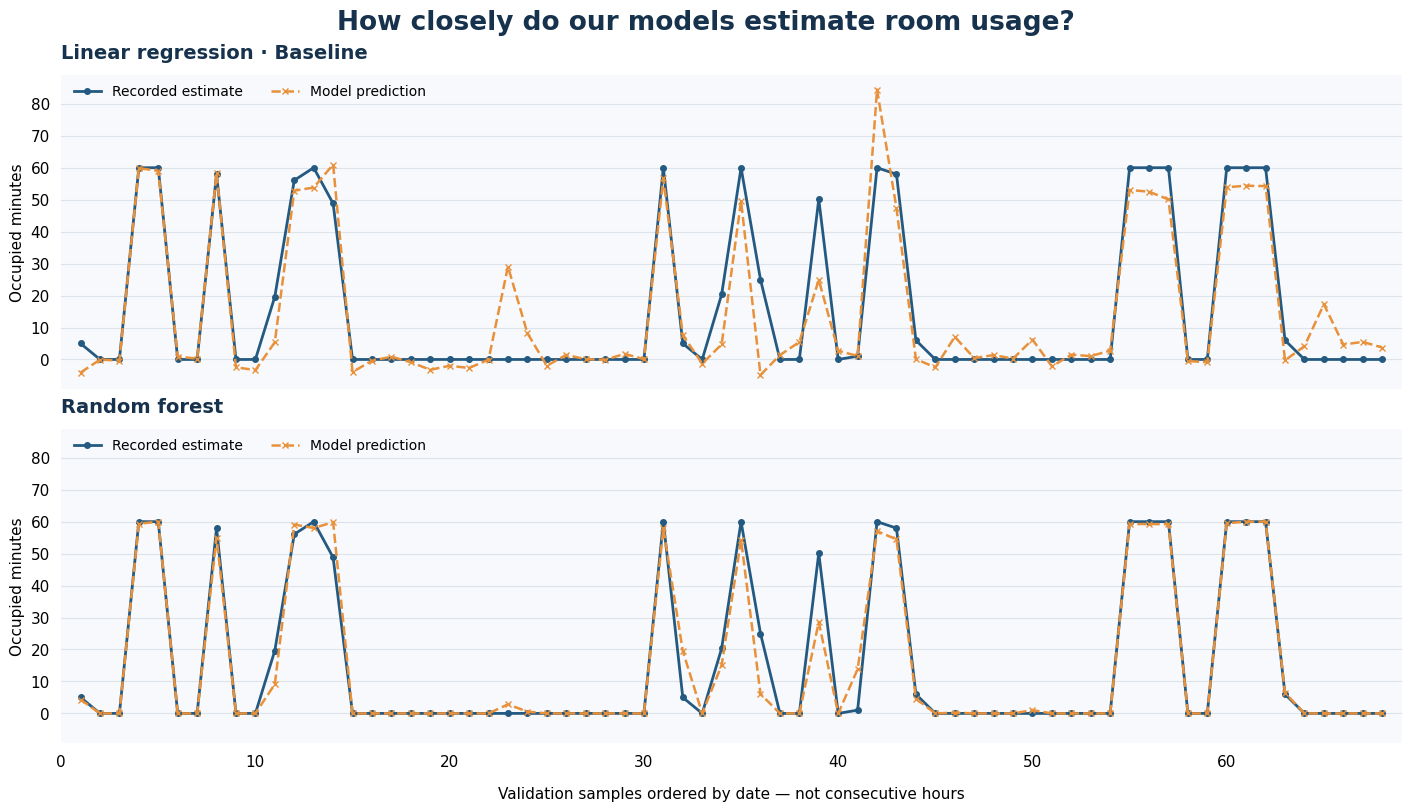

In [26]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

plot_data = results_comparison.sort_index()
samples = range(1, len(plot_data) + 1)

with plt.rc_context({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False
}):
    fig, axes = plt.subplots(
        2, 1, figsize=(14, 8),
        sharex=True, sharey=True,
        constrained_layout=True
    )

    fig.suptitle(
        "How closely do our models estimate room usage?",
        fontsize=19, fontweight="bold", color="#17324D"
    )

    models = [
        ("Linear regression", "Linear regression · Baseline"),
        ("Random forest", "Random forest")
    ]

    for ax, (column, title) in zip(axes, models):
        ax.set_facecolor("#F7F9FC")

        ax.plot(
            samples,
            plot_data["Target occupied minutes"],
            color="#245A81",
            linewidth=2,
            marker="o",
            markersize=4,
            label="Recorded estimate"
        )

        ax.plot(
            samples,
            plot_data[column],
            color="#E8913A",
            linewidth=1.8,
            linestyle="--",
            marker="x",
            markersize=5,
            label="Model prediction"
        )

        ax.set_title(
            title, loc="left",
            fontsize=14, fontweight="bold",
            color="#17324D", pad=12
        )

        ax.set_ylabel("Occupied minutes")
        ax.grid(axis="y", color="#DDE3EB", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(axis="both", length=0, pad=8)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.margins(x=0.015)

        ax.legend(
            loc="upper left",
            bbox_to_anchor=(0, 1.01),
            ncol=2,
            frameon=False,
            fontsize=10
        )

    axes[1].set_xlabel(
        "Validation samples ordered by date — not consecutive hours",
        labelpad=12
    )

    plt.savefig(
        "actual_vs_predicted_models.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

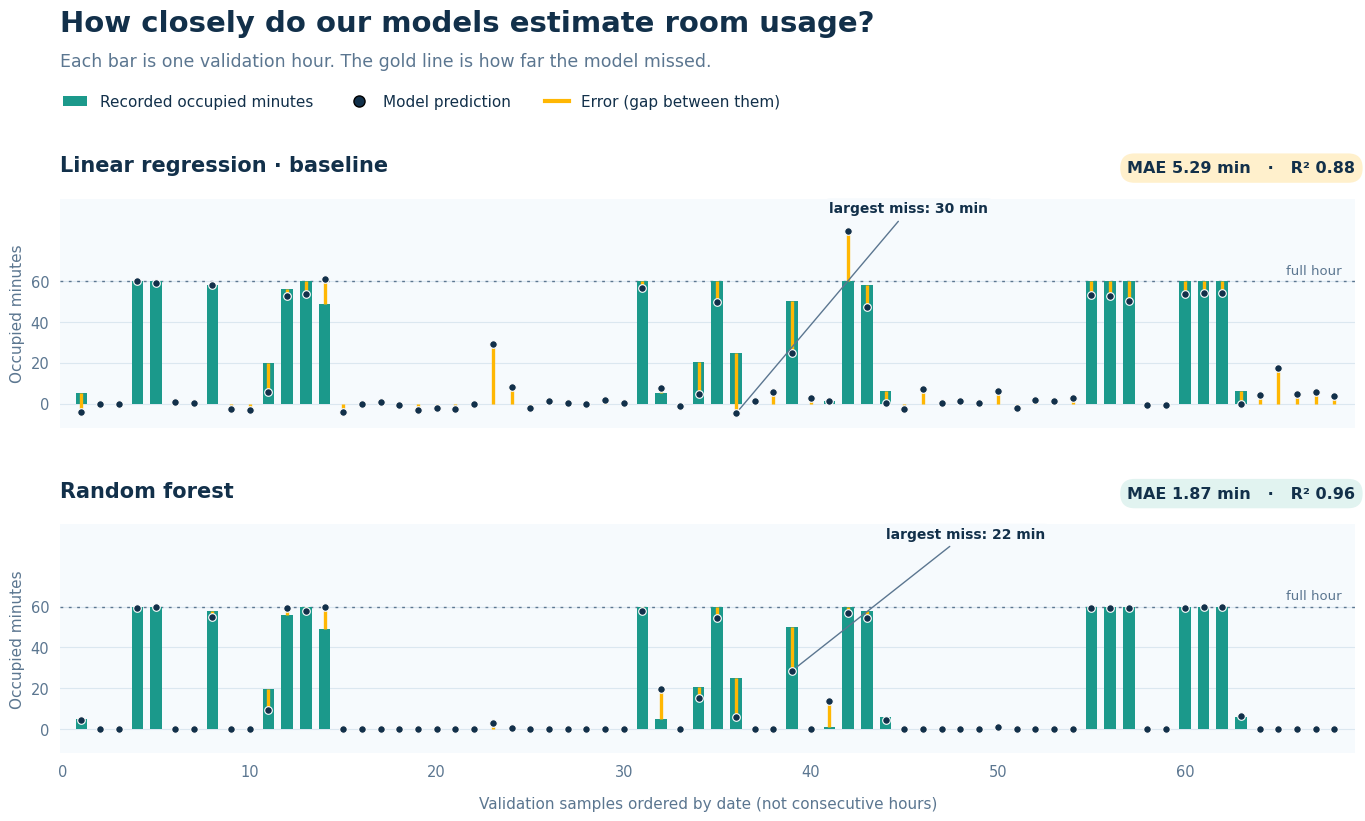

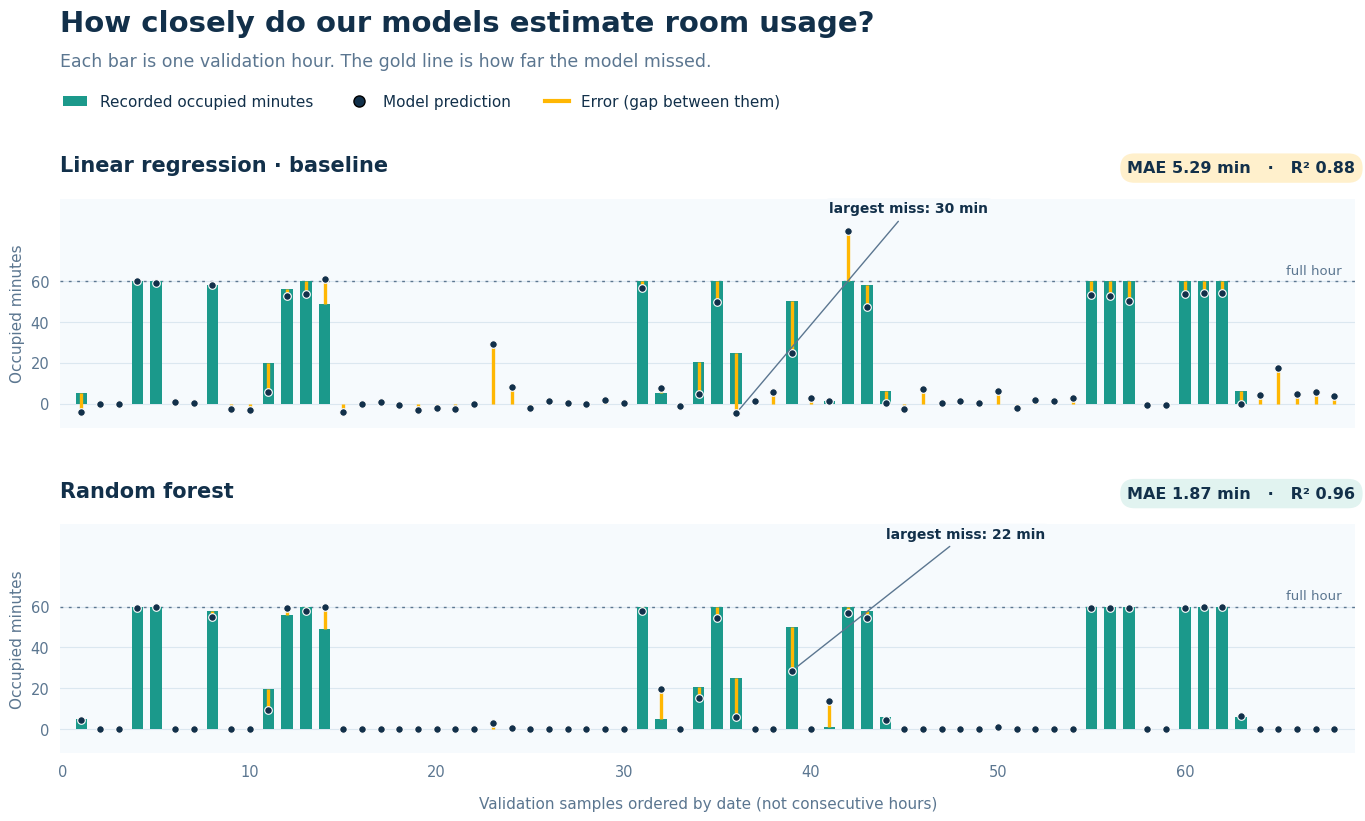

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Colors match the presentation (Daylight style)
INK, TEAL, SUN, MUTE = "#12304A", "#1B998B", "#FFB703", "#5B7690"
GRID, PANEL, SUN_SOFT, TEAL_SOFT = "#DBE7F0", "#F6FAFD", "#FFF0CC", "#E1F3F0"

plt.rcParams["font.family"] = ["Poppins", "Calibri", "DejaVu Sans"]  # first one installed wins


def plot_model_comparison(results_comparison, save_path="actual_vs_predicted_models.png"):
    data = results_comparison.sort_index()
    actual = data["Target occupied minutes"].to_numpy(dtype=float)
    x = np.arange(1, len(data) + 1)

    models = [
        ("Linear regression", "Linear regression · baseline", SUN_SOFT),
        ("Random forest", "Random forest", TEAL_SOFT),
    ]

    fig, axes = plt.subplots(2, 1, figsize=(14, 8.6), sharex=True, sharey=True,
                             gridspec_kw={"hspace": 0.42})
    fig.subplots_adjust(top=0.735, bottom=0.09, left=0.06, right=0.985)

    # Title block
    fig.text(0.06, 0.955, "How closely do our models estimate room usage?",
             fontsize=21, fontweight="bold", color=INK, ha="left", va="top")
    fig.text(0.06, 0.905, "Each bar is one validation hour. The gold line is how far the model missed.",
             fontsize=12.5, color=MUTE, ha="left", va="top")
    fig.legend(
        handles=[
            Patch(facecolor=TEAL, label="Recorded occupied minutes"),
            Line2D([0], [0], marker="o", color="none", markerfacecolor=INK, markersize=8, label="Model prediction"),
            Line2D([0], [0], color=SUN, linewidth=3, label="Error (gap between them)"),
        ],
        loc="upper left", bbox_to_anchor=(0.052, 0.872), ncol=3, frameon=False, fontsize=11,
        labelcolor=INK, handlelength=1.6, columnspacing=2.2,
    )

    all_pred = np.concatenate([data[m[0]].to_numpy(dtype=float) for m in models])
    ymin, ymax = min(0, all_pred.min()) - 7, max(60, all_pred.max()) + 16

    for ax, (col, title, pill_fill) in zip(axes, models):
        pred = data[col].to_numpy(dtype=float)
        err = pred - actual
        mae = np.abs(err).mean()
        r2 = 1 - (err ** 2).sum() / ((actual - actual.mean()) ** 2).sum()

        ax.set_facecolor(PANEL)
        for s in ax.spines.values():
            s.set_visible(False)

        ax.axhline(60, color=MUTE, linewidth=1, linestyle=(0, (2, 4)), zorder=1)
        ax.text(x[-1] + 0.4, 62, "full hour", color=MUTE, fontsize=9.5, va="bottom", ha="right")
        ax.bar(x, actual, width=0.62, color=TEAL, zorder=2)
        ax.vlines(x, actual, pred, color=SUN, linewidth=2.4, zorder=3)
        ax.scatter(x, pred, s=30, color=INK, zorder=4, edgecolor="white", linewidth=0.8)

        # Call out the single biggest miss
        i = int(np.abs(err).argmax())
        right_side = x[i] > len(x) * 0.7
        ax.annotate(
            f"largest miss: {abs(err[i]):.0f} min",
            xy=(x[i], pred[i]),
            xytext=(x[i] + (-5 if right_side else 5), ymax - 5),
            ha="right" if right_side else "left", va="center",
            fontsize=10, color=INK, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.25", facecolor=PANEL, edgecolor="none", alpha=0.95),
            arrowprops=dict(arrowstyle="-", color=MUTE, linewidth=1, shrinkA=2, shrinkB=4),
            zorder=5,
        )

        ax.set_ylim(ymin, ymax)
        ax.set_yticks([0, 20, 40, 60])
        ax.set_ylabel("Occupied minutes", color=MUTE, fontsize=11)
        ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
        ax.set_axisbelow(True)
        ax.tick_params(length=0, colors=MUTE, labelsize=10.5, pad=8)
        ax.margins(x=0.012)

        # Header: model name on the left, scores on the right
        ax.text(0, 1.1, title, transform=ax.transAxes, fontsize=15, fontweight="bold",
                color=INK, ha="left", va="bottom")
        ax.text(1, 1.1, f"MAE {mae:.2f} min   ·   R² {r2:.2f}", transform=ax.transAxes,
                fontsize=11.5, fontweight="bold", color=INK, ha="right", va="bottom",
                bbox=dict(boxstyle="round,pad=0.45,rounding_size=0.9", facecolor=pill_fill, edgecolor="none"))

    axes[1].set_xlabel("Validation samples ordered by date (not consecutive hours)",
                       color=MUTE, fontsize=11, labelpad=12)
    axes[1].set_xticks(range(0, len(x) + 1, 10))

    fig.savefig(save_path, dpi=300, facecolor="white")
    plt.show()
    return fig


plot_model_comparison(results_comparison)

## 8 Evaluate on Test
Prepare test inputs, predict with random forest, and calculate Test MAE and R²

In [16]:
import numpy as np

X_test_hourly = test_hourly[features]
y_test_hourly = test_hourly["occupied_minutes"]

In [17]:

test_predictions = forest_model.predict(X_test_hourly)
test_predictions = np.clip(test_predictions, 0, 60)

test_mae = mean_absolute_error(
y_test_hourly,
test_predictions
)

print("Random Forest Test MAE:", round(test_mae, 4))
print("Random Forest Test R²:", round(r2_score(y_test_hourly, test_predictions), 4))


Random Forest Test MAE: 1.7519
Random Forest Test R²: 0.9758


## 9 Inspect test results
Show individual errors and summarize them for mostly empty and mostly occupied hours.

In [18]:
results = pd.DataFrame({
"Actual": y_test_hourly,
"Predicted": test_predictions
})

results["Absolute_Error"] = (
results["Actual"] - results["Predicted"]
).abs()

results["Actual_State"] = np.where(
results["Actual"] < 30,
"Mostly empty",
"Mostly occupied"
)

print("MAE by actual occupancy group:")
display(
results.groupby("Actual_State")["Absolute_Error"]
.agg(["count", "mean"])
.round(3)
)

print("\nSample predictions:")
display(results.head(10).round(2))



MAE by actual occupancy group:


,count,mean
Actual_State,,
Mostly empty,49,0.761
Mostly occupied,19,4.308



Sample predictions:


,Actual,Predicted,Absolute_Error,Actual_State
date,,,,
2015-02-16 19:00:00,0.00,0.00,0.00,Mostly empty
2015-02-17 08:00:00,19.32,5.18,14.14,Mostly empty
2015-02-16 22:00:00,0.00,0.00,0.00,Mostly empty
2015-02-09 13:00:00,37.38,32.83,4.55,Mostly occupied
2015-02-17 16:00:00,60.00,60.00,0.00,Mostly occupied
2015-02-17 10:00:00,60.00,58.88,1.12,Mostly occupied
2015-02-15 02:00:00,0.00,0.00,0.00,Mostly empty
2015-02-15 13:00:00,0.00,0.42,0.42,Mostly empty
2015-02-03 00:00:00,0.00,0.00,0.00,Mostly empty


## 10 Confusion Matrix

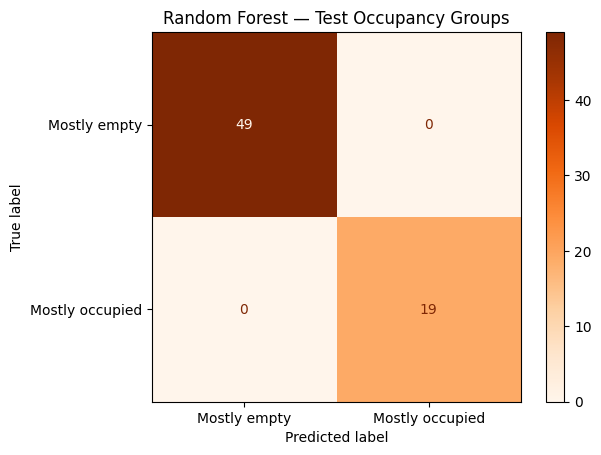

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

actual_group = (results["Actual"] >= 30).astype(int)
predicted_group = (results["Predicted"] >= 30).astype(int)

ConfusionMatrixDisplay.from_predictions(
    actual_group,
    predicted_group,
    labels=[0, 1],
    display_labels=["Mostly empty", "Mostly occupied"],
    cmap="Oranges"
)

plt.title("Random Forest — Test Occupancy Groups")
plt.show()

## Save Pipelines
Save the trained random forest pipeline and linear Regression to a .joblib file.

In [20]:
#The choosen model pipline
import joblib
from sklearn.pipeline import Pipeline

# Random forest uses the original 12 hourly features
saved_pipeline = Pipeline([
    ("model", forest_model)
])

joblib.dump(saved_pipeline, "Random_Forest.joblib")

['Random_Forest.joblib']

In [21]:
# Save the fitted linear regression pipeline

joblib.dump(
    regression_pipeline,
    "linear_regression_pipeline.joblib"
)

['linear_regression_pipeline.joblib']

## Save Example Data for the Demo
Save one test hour with some recorded occupancy to demo_hour.csv. Include only the 12 sensor features used by the model.

In [22]:
demo_hour = test_hourly[
    test_hourly["occupied_minutes"] > 0
].iloc[[0]]

demo_hour[features].to_csv(
    "demo_hour.csv",
    index=False
)

In [23]:
display(demo_hour)

,Temperature_min,Temperature_max,Temperature_median,Humidity_min,Humidity_max,Humidity_median,CO2_min,CO2_max,CO2_median,Light_min,Light_max,Light_median,occupied_share,readings,occupied_minutes
date,,,,,,,,,,,,,,,
2015-02-17 08:00:00,20.566667,20.79,20.6,30.39,30.945,30.39,773.0,840.5,790.666667,0.0,419.0,0.0,0.322034,59,19.322034
